In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1. Load Seaborn's built-in Penguins example dataset
df = sns.load_dataset('penguins')
print("--- First 5 Rows ---")
print(df.head())

--- First 5 Rows ---
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  


In [3]:
# 2. Detect missing values using isnull().any() and isnull().sum()
print("\n--- Any Missing Values Per Column ---")
print(df.isnull().any())

print("\n--- Missing Values Count Per Column ---")
print(df.isnull().sum())


--- Any Missing Values Per Column ---
species              False
island               False
bill_length_mm        True
bill_depth_mm         True
flipper_length_mm     True
body_mass_g           True
sex                   True
dtype: bool

--- Missing Values Count Per Column ---
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


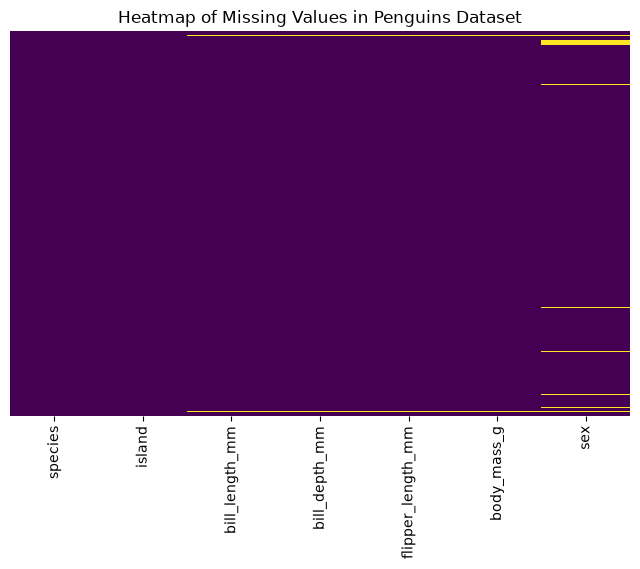

In [4]:
# 3. Visualize missing values using a Seaborn heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Heatmap of Missing Values in Penguins Dataset')
plt.show()

In [5]:
# 4. Remove completely empty records (or rows where all values are missing) using dropna()
# Note: Use how='all' to drop only completely empty records, or dropna() without arguments to drop any row with a null value.
df_cleaned = df.dropna(how='all').copy()
print("\nShape after removing completely empty records:", df_cleaned.shape)


Shape after removing completely empty records: (344, 7)


In [6]:
# 5. Fill missing categorical values using fillna() and the mode
categorical_cols = df_cleaned.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    mode_value = df_cleaned[col].mode()[0]
    df_cleaned[col] = df_cleaned[col].fillna(mode_value)

print("\n--- Missing Values After Filling Categorical Columns ---")
print(df_cleaned[categorical_cols].isnull().sum())


--- Missing Values After Filling Categorical Columns ---
species    0
island     0
sex        0
dtype: int64


C:\Users\imran\AppData\Local\Temp\ipykernel_167512\3456387878.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_cleaned.select_dtypes(include=['object', 'category']).columns


In [7]:
# 6. Estimate and fill missing numerical values using interpolate(), bfill(), and ffill()
numerical_cols = df_cleaned.select_dtypes(include=['float64', 'int64']).columns

# Create copies if you want to demonstrate or compare all three methods separately:
df_interpolated = df_cleaned.copy()
df_interpolated[numerical_cols] = df_interpolated[numerical_cols].interpolate()

df_bfill = df_cleaned.copy()
df_bfill[numerical_cols] = df_bfill[numerical_cols].bfill()

df_ffill = df_cleaned.copy()
df_ffill[numerical_cols] = df_ffill[numerical_cols].ffill()

# Or apply them sequentially on the main dataframe (interpolate, then ffill/bfill for any edge nulls)
df_cleaned[numerical_cols] = df_cleaned[numerical_cols].interpolate().ffill().bfill()

print("\n--- Final Missing Values Count Across All Columns ---")
print(df_cleaned.isnull().sum())


--- Final Missing Values Count Across All Columns ---
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
